In [2]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
from langchain_community.vectorstores import Chroma

from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
from langgraph.prebuilt import ToolNode
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from typing import Annotated, operator
from langchain_core.tools import tool
from tavily import TavilyClient

load_dotenv()

C:\Users\sanke\AppData\Local\Temp\ipykernel_26604\4052309781.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader # for image + table+ text kind of. data use --> unstructured.io libraries


True

In [3]:
# 1 load the pdf files
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()

# 2 . split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = text_splitter.split_documents(raw_docs)
print(len(chunks))

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
    # persist_directory="../chroma_db". # this is optional for this run
)

vectorstore.add_documents(chunks)

51


C:\Users\sanke\AppData\Local\Temp\ipykernel_26604\4215422859.py:12: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(


['4a311932-33e4-4647-bc04-3df93ac0e7de',
 'cc1797c6-9b2a-4203-8329-bc15bbbf84dc',
 '945f988e-c00a-4ddd-bd30-e3084125ace2',
 'a8ca0a38-f9ac-439b-b53a-38151b2bfc6f',
 '8ed7a216-fdba-4eb0-93d2-d8b346ae47f7',
 '6ef51004-4762-4260-abd0-c72a5869dbce',
 '96115aaa-8b0c-4e3c-aa91-1ca4162f3bb5',
 'f9d37530-c6a4-4c44-8131-74f65b9c0021',
 '6e985319-a6b1-4c83-955e-f33939cfc13b',
 'f46fc069-4108-4ff2-aad2-79f35497bae0',
 '712d8dda-2ef6-4236-a1e2-aeb1561a55f4',
 '6a3eeb02-ee31-4424-ab1d-79ddb2fcaeaf',
 '93daef58-78c6-48cc-a23a-1a5e3d023cc3',
 '71f0b525-77ef-4732-882a-6ceca08642f5',
 '3c35f242-02dc-458f-b119-6eb3126fc971',
 '562a34fe-4ed6-4d2b-ab68-72d4b85ba87b',
 '70a60eef-37d3-41f4-805a-c232fbbc06d3',
 '343403a1-8a1b-4ace-8a88-bf122a32cf75',
 '84a37379-5c26-4e6d-872c-827c2b95cace',
 '243a4b8e-5930-4b8e-8b49-ed5738377779',
 '7dd59399-259b-426e-9de3-3d7dda104f3e',
 'ac08d0ba-8e9d-4bdb-a0a1-1ca3c31d2ff7',
 '468898fb-4648-4b31-b6e8-2d9cef05df8b',
 '73b12e73-0923-4176-969c-3961caba0a9b',
 'e03c4328-5c87-

In [4]:
llm = ChatOpenAI(model="gpt-4o-mini") # this is for route_questions and generation
agent_llm = ChatOpenAI(model="gpt-5-mini")

In [5]:
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool



class RouteDecision(BaseModel):
    needs_retrieval: bool

In [6]:
# Define the tools
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k:int = 3):
    """ 
    Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages.
    
    """

    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context,docs


import os

@tool(response_format="content_and_artifact")
def web_search(query:str, max_results:int = 3):
    """
    Search the web for relevant information.
    Adjust max_results (default 3) to retrieve more or fewer results.
    """
    client = TavilyClient(api_key=os.getenv("TVLY_API_KEY"))
    response = client.search(query, max_results=max_results)
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return content, docs

In [7]:
tools = [web_search, vector_store_search]
agent_llm_with_tools = agent_llm.bind_tools(tools)
tool_node = ToolNode(tools)

In [8]:
#agent_llm.invoke('tell me todays news')

In [9]:
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [10]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

In [11]:
def agent(state: AgenticRAGState) -> dict:
    messages = state['messages']
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]
        
    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}
    

def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [12]:
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [13]:
from typing import Literal
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [14]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)


graph = graph_builder.compile()

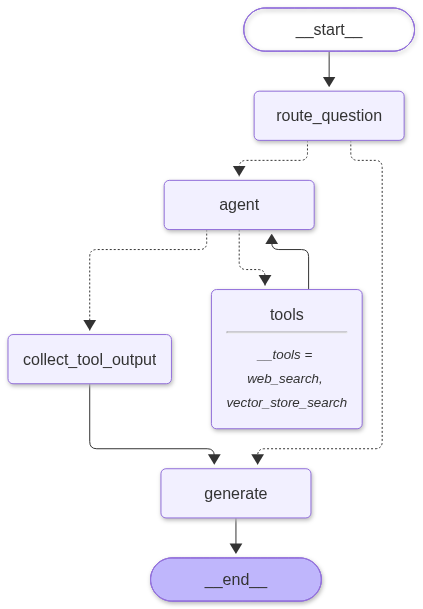

In [15]:
graph

In [16]:
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [17]:
result_vs

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 118, 'prompt_tokens': 438, 'total_tokens': 556, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EoVC5jLjmGcnWv4gZvHcmgmuyloeE', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None, 'normalized_finish_reason': 'tool_call'}, id='lc_run--01a2185c-10ce-71d1-b997-371165a5c1c0-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': 'electric vehicle adoption impact on oil demand displacement scenarios fleet turnover oil demand through 2050 Will EVs Dampen the Oil Price Shock?',

In [18]:
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

In [19]:
result_web

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 97, 'prompt_tokens': 431, 'total_tokens': 528, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EoVCHHE0ut02mSzl1OPmaKMEapBRi', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None, 'normalized_finish_reason': 'tool_call'}, id='lc_run--01a2185c-40fd-75f1-81b4-d8f1d3b09c43-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'New Delhi current temperature now', 'max_results': 5}, 'id': 'call_XFClgqNhty3DLiopy8BQca59', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'

In [20]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai"
result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

In [21]:
result_both

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 286, 'prompt_tokens': 444, 'total_tokens': 730, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EoVCezbkNBOODs7DlIfWxHFXu9SMj', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None, 'normalized_finish_reason': 'tool_call'}, id='lc_run--01a2185c-9b00-7673-8d4a-3680bdb16df9-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': '2030 oil demand projection Will EVs Dampen the Oil Price Shock? 2030 oil demand displacement 2030 demand scenario', 'k': 5}, 'id': 'call_A16NbqM7Y

In [22]:
print(result_both['generation'])

The EV report projects that in the near term through 2030, EV penetration will reduce global oil demand growth by meaningful but modest volumes. It suggests that this reduction is likely to delay demand peaks rather than prevent them, offering only partial insulation against supply-driven price shocks.

In terms of the weather in Mumbai, as of the most recent update, the current temperature is 27.8°C with conditions described as a smoky haze. The humidity level is at 57%, and there is a 3% chance of rain. The wind is coming from the north-northwest at a speed of 7.9 kph.
